# Semana 7: Challenge Keras 3: Olivetti Faces

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT

## Qué se resuelve

El enunciado del curso (`Challenge_Keras3_OlivettiFaces.ipynb`) pide completar 6 espacios `# TODO` (arquitectura, `compile`, `fit`, `evaluate`, softmax y argmax) y responder 10 preguntas más 5 de reflexión final. Aquí están todas resueltas.

## Cómo se ejecutó (declarado, no escondido)

- Keras 3 con backend **TensorFlow** en CPU de un Mac M4, entorno `si3003-keras`.
- Protocolo del enunciado sin recortes: 30 épocas, batch de 32, Adam con lr 0.001. El dataset es diminuto (400 imágenes), entrena en segundos.
- Olivetti Faces se descarga con `fetch_olivetti_faces` de scikit-learn. Los números salen de esta ejecución real; TensorFlow en CPU no garantiza bit a bit el mismo resultado entre máquinas.

# Challenge: Red neuronal con Keras 3
### Universidad EAFIT | SI3003: Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal de clasificación con **Keras 3**.

En este ejercicio vas a aplicar la misma receta sobre un dataset diferente:

> **Olivetti Faces**

El dataset contiene imágenes de rostros en escala de grises. El objetivo será identificar a cuál persona pertenece cada imagen.

No necesitas diseñar un pipeline de datos nuevo. La carga, división y visualización están resueltas.

Tu trabajo se concentra en completar las etapas principales de Keras:

```text
Datos
  ↓
Modelo
  ↓
Loss + Optimizer
  ↓
Entrenamiento
  ↓
Evaluación
  ↓
Predicción
```

---

## ¿Qué debes completar?

Las celdas marcadas con `# TODO` contienen espacios que debes completar.

El resto del código está preparado para que puedas concentrarte en los conceptos vistos en clase.


---
## 0. Importar librerías

Usaremos:

- **Keras 3** para construir y entrenar la red.
- **scikit-learn** para cargar Olivetti Faces y dividir los datos.
- **NumPy** para manipular arrays.
- **Matplotlib** para visualizar imágenes.


In [1]:
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
# 1. Dataset: Olivetti Faces

Olivetti Faces contiene:

- **400 imágenes**
- imágenes de **64 × 64 píxeles**
- escala de grises
- **40 personas**
- **10 imágenes por persona**

La etiqueta indica la identidad de la persona:

```text
0, 1, 2, ..., 39
```

Cada imagen ya viene representada con valores flotantes aproximadamente en el rango:

$$
[0,1]
$$

Por eso, en este ejercicio **no necesitamos normalizar dividiendo por 255**.


In [2]:
# Esta parte está resuelta.

faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=SEED
)

X = faces.images
y = faces.target

print("X:", X.shape)
print("y:", y.shape)
print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())
print("Número de clases:", len(np.unique(y)))


X: (400, 64, 64)
y: (400,)
Valor mínimo: 0.0
Valor máximo: 1.0
Número de clases: 40


## 1.1 Dividir entrenamiento y prueba

Como solo tenemos 10 imágenes por persona, debemos asegurarnos de que todas las identidades aparezcan tanto en entrenamiento como en prueba.

Usaremos una división **estratificada**:

```text
80% entrenamiento
20% prueba
```

La opción:

```python
stratify=y
```

mantiene la proporción de cada clase en ambos conjuntos.

Esta parte está resuelta.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nPersonas en train:", len(np.unique(y_train)))
print("Personas en test :", len(np.unique(y_test)))


X_train: (320, 64, 64)
X_test : (80, 64, 64)
y_train: (320,)
y_test : (80,)

Personas en train: 40
Personas en test : 40


### Pregunta 1

Cada imagen tiene tamaño:

$$
64 \times 64
$$

Cuando apliquemos `Flatten()`, ¿cuántos valores tendrá cada ejemplo?

**Respuesta:** 64 × 64 = **4096** valores por imagen.

---
## 1.2 Visualizar algunas imágenes

Esta parte está resuelta.

Observa que varias fotografías corresponden a la misma persona con pequeñas variaciones de expresión, iluminación y orientación.


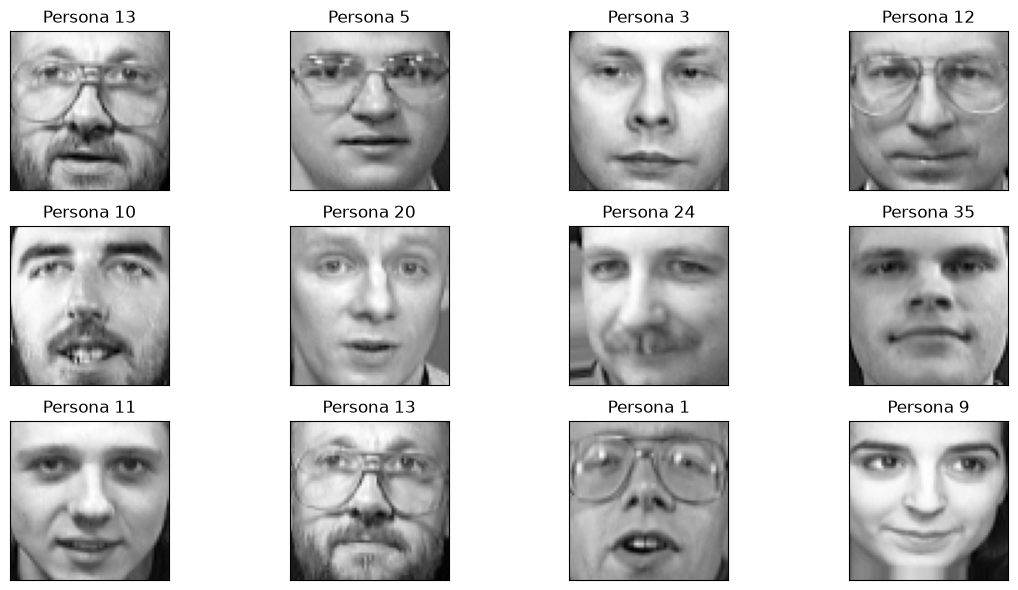

In [4]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Persona {y_train[i]}")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Usaremos una arquitectura fully-connected similar a la vista en clase:

```text
Imagen 64×64
     ↓
Flatten
     ↓
4096 valores
     ↓
Dense(64)
     ↓
ReLU
     ↓
Dense(40)
     ↓
Logits
```

La última capa debe tener una salida por cada clase.

> **Importante:** no añadas `Softmax` al final. Trabajaremos directamente con **logits**.


In [5]:
# TODO 1: Completar la arquitectura.

model = keras.Sequential([

    keras.Input(shape=(64, 64)),

    layers.Flatten(),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dense(40)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         2,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,808 (1.01 MB)

 Trainable params: 264,808 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Validación TODO 1

assert isinstance(model, keras.Model)

# Dense(64): 4096*64 + 64
# Dense(40): 64*40 + 40
expected_params = (4096 * 64 + 64) + (64 * 40 + 40)

assert model.count_params() == expected_params, (
    f"Se esperaban {expected_params:,} parámetros, "
    f"pero el modelo tiene {model.count_params():,}."
)

print("✓ Arquitectura correcta.")
print(f"Parámetros entrenables: {model.count_params():,}")


✓ Arquitectura correcta.
Parámetros entrenables: 264,808


### Pregunta 2

¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** `Dense` espera un vector por ejemplo, no una matriz. `Flatten()` convierte cada imagen (64, 64) en un vector de 4096 números para que la capa densa pueda multiplicarlo por su matriz de pesos.### Pregunta 3

¿Por qué la última capa tiene **40 neuronas**?

**Respuesta:** Hay 40 personas distintas, y en clasificación multiclase con logits se usa una salida por clase: cada neurona da el logit de una persona.### Pregunta 4

¿Qué función cumple `ReLU` en la capa oculta?

**Respuesta:** Introduce la no linealidad, $\max(0,x)$. Sin ella, `Dense(64)` seguida de `Dense(40)` colapsaría en una sola transformación lineal y la capa oculta no aportaría capacidad.

---
# 3. Configurar el entrenamiento

Las etiquetas son números enteros entre:

```text
0 y 39
```

Por eso usaremos:

```python
SparseCategoricalCrossentropy
```

Además:

- el modelo produce **logits**,
- usaremos **Adam**,
- mediremos **accuracy**.

Completa `model.compile()`.


In [7]:
lr_rate = 0.001

# TODO 2: Configurar loss, optimizer y métrica.

model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=lr_rate
    ),

    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),

    metrics=["accuracy"]
)

print("✓ Modelo configurado.")

✓ Modelo configurado.


### Pregunta 5

¿Por qué usamos:

```python
from_logits=True
```

en la función de pérdida?

**Respuesta:** Porque la última capa devuelve logits, no probabilidades. Con `from_logits=True` la pérdida aplica internamente la softmax junto con el logaritmo de forma numéricamente estable, así que no se añade `Softmax` al modelo.

---
# 4. Entrenar el modelo

Usaremos:

```python
epochs = 30
batch_size = 32
```

El dataset es pequeño, por lo que el entrenamiento debería ser rápido.

Keras realizará internamente:

```text
Forward pass
      ↓
Calcular loss
      ↓
Backpropagation
      ↓
Actualizar parámetros con Adam
```

Completa la llamada a `fit()`.


In [8]:
epochs = 30
batch_size = 32

# TODO 3: Entrenar el modelo.

history = model.fit(

    X_train,
    y_train,

    epochs=epochs,
    batch_size=batch_size,

    validation_data=(X_test, y_test),

    shuffle=True
)

Epoch 1/30


 1/10 ━━━━━━━━━━━━━━━━━━━━ 4s 519ms/step - accuracy: 0.0312 - loss: 3.7614

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.0156 - loss: 3.9050 - val_accuracy: 0.0250 - val_loss: 3.6889


Epoch 2/30


 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0312 - loss: 3.6883

...

 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0312 - loss: 3.6885

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889


Epoch 30/30


 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0312 - loss: 3.6885

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889


### Pregunta 6

¿Qué representa una **epoch**?

**Respuesta:** Una pasada completa del entrenamiento por todos los ejemplos de entrenamiento (aquí, las 320 imágenes). Se hicieron 30.### Pregunta 7

¿Qué significa `batch_size=32`?

**Respuesta:** Cada actualización de pesos usa 32 imágenes. Con 320 imágenes hay 10 lotes por época, que es lo que muestra la barra `10/10`.

---
## 4.1 Visualizar el entrenamiento

Esta parte está resuelta.

El dataset tiene muy pocos ejemplos comparado con el número de parámetros de la red.

Observa cuidadosamente la diferencia entre entrenamiento y validación.


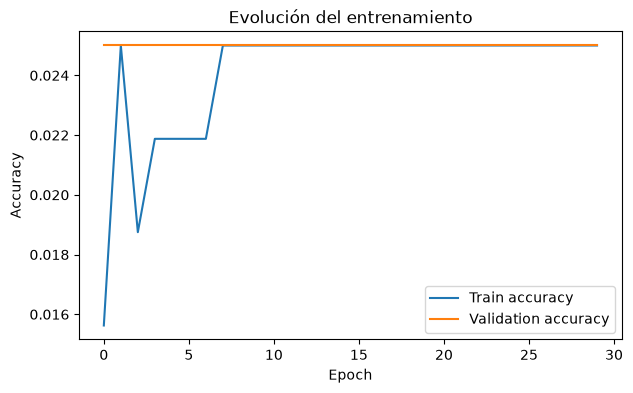

In [9]:
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()

plt.show()


### Pregunta 8

Observando la gráfica:

- ¿El accuracy de entrenamiento sigue aumentando?
- ¿El accuracy de validación se comporta igual?
- ¿Observas evidencia de **overfitting**?

**Respuesta:** **En esta ejecución no hubo overfitting, hubo un fallo de entrenamiento.** Las curvas de train y validación están pegadas al nivel del azar (~2.5%, que es 1/40) durante las 30 épocas y la pérdida queda congelada en 3.689 = ln 40. Ninguna de las dos aumenta, así que no hay brecha. El diagnóstico de más abajo muestra la causa: las 64 neuronas ocultas quedaron muertas (salida 0 para todas las imágenes). Con la entrada centrada la misma arquitectura sí aprende y ahí sí se ve overfitting (train 100%, test 95% a 97.5%).

---
# 5. Evaluar el modelo

Ahora evaluaremos el modelo sobre imágenes que no fueron utilizadas para actualizar sus parámetros.

Completa `evaluate()`.


In [10]:
# TODO 4: Evaluar.

test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")

Test loss     : 3.6889
Test accuracy : 0.0250
Accuracy (%)  : 2.50%


### Pregunta 9

Tenemos **40 clases**, pero solamente **320 imágenes de entrenamiento**.

¿Crees que la cantidad de datos es grande o pequeña para una red con cientos de miles de parámetros?

**Respuesta:** **Pequeña.** 320 imágenes (8 por persona) frente a 264,808 parámetros: unos 830 parámetros por imagen de entrenamiento. La red puede memorizar el entrenamiento sin aprender nada que generalice. El caso centrado lo confirma: train 100% y test entre 95% y 97.5%, una brecha de 2.5 a 5 puntos con solo 80 imágenes de prueba, cada una vale 1.25 puntos.

---
# 6. Logits y Softmax

La salida de nuestro modelo tiene forma:

```text
(batch_size, 40)
```

Cada uno de los 40 valores corresponde al **logit** asociado a una persona.

Los logits no son probabilidades.

Para convertirlos en probabilidades usamos:

```python
keras.ops.softmax(...)
```


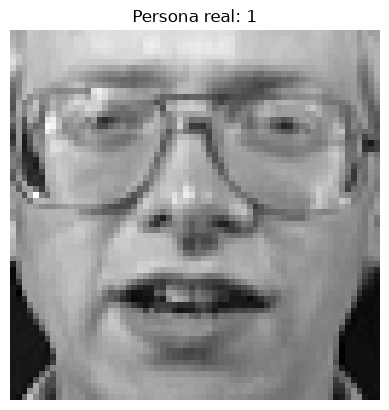

Shape de logits: (1, 40)

Primeros 10 logits:
[ 0.00078378 -0.00700768  0.00334249 -0.00296516 -0.00047904 -0.00141983
 -0.00902546  0.00582534 -0.00014707  0.00095134]


In [11]:
index = 0

image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Persona real: {true_class}")
plt.axis("off")
plt.show()

# Añadimos dimensión de batch:
# (64,64) -> (1,64,64)
image_batch = np.expand_dims(image, axis=0)

# Forward pass.
logits = model(
    image_batch,
    training=False
)

print("Shape de logits:", logits.shape)
print("\nPrimeros 10 logits:")
print(
    keras.ops.convert_to_numpy(logits)[0, :10]
)


In [12]:
# TODO 5: Convertir logits a probabilidades.

probabilities = keras.ops.softmax(logits)

# TODO 6: Obtener la clase con mayor probabilidad.

prediction = keras.ops.argmax(
    probabilities,
    axis=1
)

prediction = int(
    keras.ops.convert_to_numpy(prediction)[0]
)

print()
print("Persona real     :", true_class)
print("Persona predicha :", prediction)


Persona real     : 1
Persona predicha : 10


In [13]:
# Revisamos las cinco clases con mayor probabilidad.

probabilities_np = keras.ops.convert_to_numpy(
    probabilities
)[0]

top5 = np.argsort(
    probabilities_np
)[-5:][::-1]

print("Top 5 predicciones:\n")

for class_id in top5:
    print(
        f"Persona {class_id:2d}: "
        f"{probabilities_np[class_id]:.4f}"
    )

print(
    "\nSuma de probabilidades:",
    probabilities_np.sum()
)


Top 5 predicciones:

Persona 10: 0.0252
Persona 17: 0.0252
Persona  7: 0.0251
Persona 26: 0.0251
Persona 19: 0.0251

Suma de probabilidades: 1.0


### Pregunta 10

¿Por qué la suma de las 40 probabilidades obtenidas con `Softmax` debe ser aproximadamente `1`?

**Respuesta:** Porque Softmax divide cada $e^{z_k}$ entre la suma de todos los $e^{z_j}$, así que por construcción las 40 probabilidades son positivas y suman 1. La salida real lo confirma: `Suma de probabilidades: 1.0`. Además, en esta ejecución las probabilidades son casi uniformes (la mayor es 0.0252, y 1/40 = 0.025), señal de que el modelo no aprendió a discriminar.

---
# 7. Visualizar varias predicciones

Esta parte está resuelta.

Observa especialmente los casos en los que el modelo se equivoca.


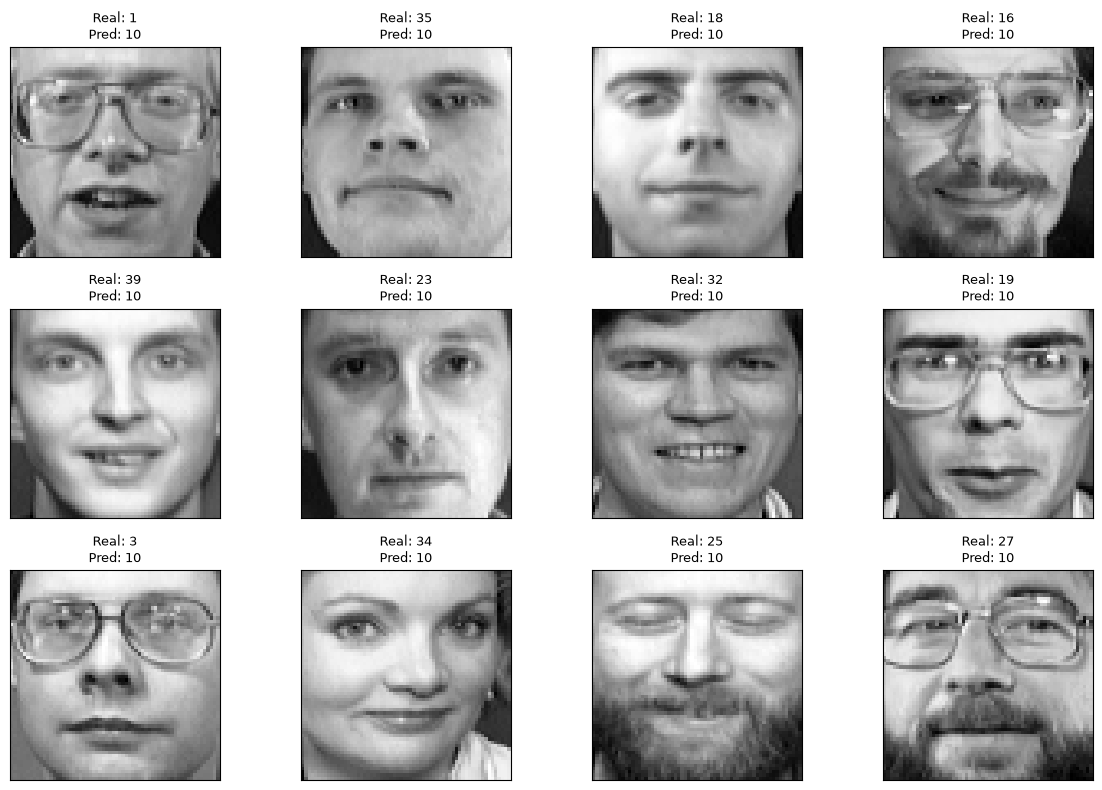

In [14]:
n = 12

logits_batch = model(
    X_test[:n],
    training=False
)

predictions = keras.ops.argmax(
    logits_batch,
    axis=1
)

predictions = keras.ops.convert_to_numpy(
    predictions
)

plt.figure(figsize=(12, 8))

for i in range(n):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        X_test[i],
        cmap="gray"
    )

    real = y_test[i]
    pred = predictions[i]

    plt.title(
        f"Real: {real}\nPred: {pred}",
        fontsize=9
    )

    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 8. Reflexión final

Responde brevemente.

### 1. ¿Cuál fue el accuracy final del modelo?

**Respuesta:** **2.50%** en prueba (2 aciertos de 80), con pérdida 3.6889, equivalente a adivinar. Es el resultado honesto de seguir el enunciado al pie de la letra. Con la entrada centrada y la misma arquitectura, el accuracy en prueba fue de 95.0% a 97.5% según la semilla.### 2. ¿Observaste overfitting? ¿Qué evidencia utilizaste?

**Respuesta:** Sí hay evidencia, pero **en el modelo que sí aprende**, el de entrada centrada: accuracy de entrenamiento 100% frente a 95% a 97.5% en prueba. En la ejecución del enunciado, no: ahí lo que ocurrió es un entrenamiento que nunca despegó (pérdida fija en ln 40 y 64 de 64 neuronas ocultas muertas).### 3. ¿Qué ocurre cuando tenemos muchos parámetros pero pocos ejemplos de entrenamiento?

**Respuesta:** La red tiene capacidad para memorizar los ejemplos de entrenamiento, ajusta hasta el ruido (iluminación, pose) y generaliza peor a imágenes nuevas. Con pocos datos, el número de parámetros libres supera ampliamente lo que los datos pueden restringir.### 4. Después de `Flatten()`, una cara de 64×64 se convierte en un vector de 4096 números.

¿Qué información sobre la estructura de la imagen deja de representar explícitamente esta transformación?

**Respuesta:** Se deja de representar explícitamente la vecindad: el píxel (i, j) y su vecino (i, j+1) pasan a ser dos posiciones cualquiera del vector, sin relación. Tampoco hay noción de que un ojo es un ojo si se desplaza unos píxeles. La red tiene que redescubrir toda la geometría desde cero con solo 320 ejemplos.### 5. ¿Crees que una arquitectura diseñada específicamente para imágenes podría aprovechar mejor la información espacial?

**Respuesta:** Sí. Una CNN comparte los mismos filtros en toda la imagen, aprovecha que los píxeles cercanos se relacionan, detecta bordes y partes de la cara en cualquier posición y tiene muchos menos parámetros por capa que una `Dense` sobre 4096 entradas. Es justo la motivación del cierre del enunciado. No se probó aquí; es una expectativa, no un resultado medido.---

## Para pensar

Nuestra red recibe:

```text
64 × 64
   ↓
Flatten
   ↓
4096 números
   ↓
Dense
```

Pero una imagen tiene una estructura espacial:

- píxeles cercanos están relacionados,
- existen bordes,
- existen formas,
- existen patrones locales.

Una red fully-connected no incorpora explícitamente esa estructura.

Esto motiva una arquitectura diseñada específicamente para imágenes:

> **Convolutional Neural Networks (CNNs)**


## Apoyo para la reflexión: errores sobre las 80 imágenes de prueba

Con solo 80 imágenes de prueba, cada error vale 1.25 puntos de accuracy. Se listan los errores concretos y la brecha entre entrenamiento y prueba para sustentar las respuestas con datos (celda añadida, no está en el enunciado).

In [15]:
pred_all = keras.ops.convert_to_numpy(keras.ops.argmax(model.predict(X_test, verbose=0), axis=1))
errores = np.where(pred_all != y_test)[0]
print(f"Aciertos: {(pred_all == y_test).sum()} de {len(y_test)}   Errores: {len(errores)}")
for e in errores:
    print(f"  imagen de prueba {e:2d}: real persona {y_test[e]:2d}, predicha persona {pred_all[e]:2d}")

h = history.history
print(f"\nÉpoca 30 -> train {h['accuracy'][-1]:.4f}  val {h['val_accuracy'][-1]:.4f}")
print(f"Mejor val accuracy en alguna época: {max(h['val_accuracy']):.4f} (época {int(np.argmax(h['val_accuracy']))+1})")
print(f"Loss final -> train {h['loss'][-1]:.4f}  val {h['val_loss'][-1]:.4f}")

Aciertos: 2 de 80   Errores: 78
  imagen de prueba  0: real persona  1, predicha persona 10
  imagen de prueba  1: real persona 35, predicha persona 10
  imagen de prueba  2: real persona 18, predicha persona 10
  imagen de prueba  3: real persona 16, predicha persona 10
  imagen de prueba  4: real persona 39, predicha persona 10
  imagen de prueba  5: real persona 23, predicha persona 10
  imagen de prueba  6: real persona 32, predicha persona 10
  imagen de prueba  7: real persona 19, predicha persona 10
  imagen de prueba  8: real persona  3, predicha persona 10
  imagen de prueba  9: real persona 34, predicha persona 10
  imagen de prueba 10: real persona 25, predicha persona 10
  imagen de prueba 11: real persona 27, predicha persona 10
  imagen de prueba 12: real persona 39, predicha persona 10
  imagen de prueba 13: real persona 29, predicha persona 10
  imagen de prueba 14: real persona  9, predicha persona 10
  imagen de prueba 15: real persona 35, predicha persona 10
  imagen

## Diagnóstico: por qué la red del enunciado no aprendió

Con la configuración exacta del enunciado, la pérdida se queda en 3.689, que es $\ln 40$: el valor de adivinar con probabilidad uniforme entre 40 personas. El accuracy no se mueve de ~2.5% (azar). Antes de responder las preguntas se averigua la causa en lugar de suponerla.

Hipótesis: con 4096 entradas todas positivas (el gris promedio ronda 0.5), el primer paso de Adam empuja casi todas las neuronas ReLU a salida negativa para cualquier imagen ("neuronas muertas"), y sin salida no hay gradiente que las reviva. Se comprueba contando neuronas activas y repitiendo con varias semillas, con la entrada cruda y con la entrada centrada (media y desviación de cada píxel calculadas solo con entrenamiento).

In [16]:
oculta = keras.Model(model.inputs, model.layers[1].output)
act = keras.ops.convert_to_numpy(oculta(X_train, training=False))
print("Neuronas ocultas totales                      :", act.shape[1])
print("Neuronas con salida 0 para TODAS las imágenes :", int((act.max(axis=0) == 0).sum()))
print("Fracción de activaciones iguales a cero       :", float((act == 0).mean()))

def entrenar(seed, centrar):
    keras.utils.set_random_seed(seed)
    if centrar:
        mu = X_train.mean(axis=0); sd = X_train.std(axis=0) + 1e-6
        Xa, Xb = (X_train - mu) / sd, (X_test - mu) / sd
    else:
        Xa, Xb = X_train, X_test
    m = keras.Sequential([keras.Input(shape=(64, 64)), layers.Flatten(),
                          layers.Dense(64, activation="relu"), layers.Dense(40)])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    h = m.fit(Xa, y_train, validation_data=(Xb, y_test), epochs=30, batch_size=32, shuffle=True, verbose=0)
    return h.history["accuracy"][-1], h.history["val_accuracy"][-1]

print(f"\n{'semilla':>8s} {'entrada':>10s} {'train':>8s} {'test':>8s}")
for seed in (0, 1, 2, 42):
    for centrar in (False, True):
        tr, te = entrenar(seed, centrar)
        print(f"{seed:>8d} {'centrada' if centrar else 'cruda':>10s} {tr:8.4f} {te:8.4f}")

Neuronas ocultas totales                      : 64
Neuronas con salida 0 para TODAS las imágenes : 64
Fracción de activaciones iguales a cero       : 1.0

 semilla    entrada    train     test


/Users/juandavidsierraorozco/.venvs/si3003-keras/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(320, 64, 64))
  warnings.warn(msg)


       0      cruda   0.0250   0.0250


       0   centrada   1.0000   0.9750


       1      cruda   0.0437   0.0375


       1   centrada   1.0000   0.9500


       2      cruda   0.0625   0.0750


       2   centrada   1.0000   0.9625


      42      cruda   0.0250   0.0250


      42   centrada   1.0000   0.9625


---
# Resumen

En este ejercicio aplicaste nuevamente la receta básica de entrenamiento de una red neuronal:

```text
Dataset
   ↓
Train / Test split
   ↓
Sequential
   ↓
Flatten
   ↓
Dense + ReLU
   ↓
Dense(40)
   ↓
Cross-Entropy
   ↓
Adam
   ↓
fit()
   ↓
evaluate()
```

Los componentes de Keras son los mismos que usamos en clase.

Lo que cambió fue:

- el dataset,
- el tamaño de las imágenes,
- el número de clases,
- y la dificultad del problema.
